In [8]:
import pandas as pd
import jieba
import re
from tqdm import tqdm
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

print("1. 正在进行文本清洗和分词...")
# 加载停用词
stopwords = set()
try:
    with open('stopword.txt', 'r', encoding='utf-8') as f:
        stopwords.update(line.strip() for line in f if line.strip())
except:
    pass # 没找到停用词文件就算了

def clean_text(text):
    text = re.sub(r'[^\w\u4e00-\u9fff]+', ' ', str(text))
    words = jieba.lcut(text)
    return [word for word in words if (word not in stopwords) and (not word.isdigit()) and (len(word) > 1)]

# 生成 cleaned_words 列
df['cleaned_words'] = df['records'].apply(clean_text)

# 生成 processed_text 列（这就是你刚才报错缺的那一列）
df['processed_text'] = df['cleaned_words'].apply(lambda x: ' '.join(x))
print("✅ processed_text 创建成功！前 3 行示例：")
print(df[['processed_text']].head(3))


print("\n2. 正在创建文档-词矩阵...")
vectorizer = CountVectorizer(max_df=0.95, min_df=2, max_features=5000)
doc_term_matrix = vectorizer.fit_transform(df['processed_text'])
print(f"✅ 词矩阵创建成功！矩阵大小: {doc_term_matrix.shape}")


print("\n3. 开始训练 LDA 模型寻找最佳主题数 (请耐心等待进度条)...")
def compute_lda_metrics(doc_term_matrix, max_topics=10, start=2, step=1):
    perplexities = []
    log_likelihoods = []
    topics_range = range(start, max_topics, step)

    for n_topics in tqdm(topics_range, desc="训练LDA"):
        lda = LatentDirichletAllocation(
            n_components=n_topics,
            max_iter=10,  # 为了快一点，这里改成了10次
            learning_method='online',
            random_state=42,
            n_jobs=-1
        )
        lda.fit(doc_term_matrix)
        perplexities.append(lda.perplexity(doc_term_matrix))
        log_likelihoods.append(lda.score(doc_term_matrix))
    return topics_range, perplexities, log_likelihoods

topics_range, perplexities, log_likelihoods = compute_lda_metrics(doc_term_matrix)
print("\n🎉 LDA 训练完成！现在你可以画图了。")

1. 正在进行文本清洗和分词...
✅ processed_text 创建成功！前 3 行示例：
                    processed_text
0  客服 你好 优惠券 怎么 不了 是不是 别的 活动 冲突 在线
1     会员价 普通 价差 多少 洗面奶 我开 会员 划算 在线
2        收货人 姓名 运动鞋 不是 本人 麻烦 尽快 回复

2. 正在创建文档-词矩阵...
✅ 词矩阵创建成功！矩阵大小: (84252, 612)

3. 开始训练 LDA 模型寻找最佳主题数 (请耐心等待进度条)...


训练LDA: 100%|██████████| 8/8 [15:23<00:00, 115.48s/it]


🎉 LDA 训练完成！现在你可以画图了。


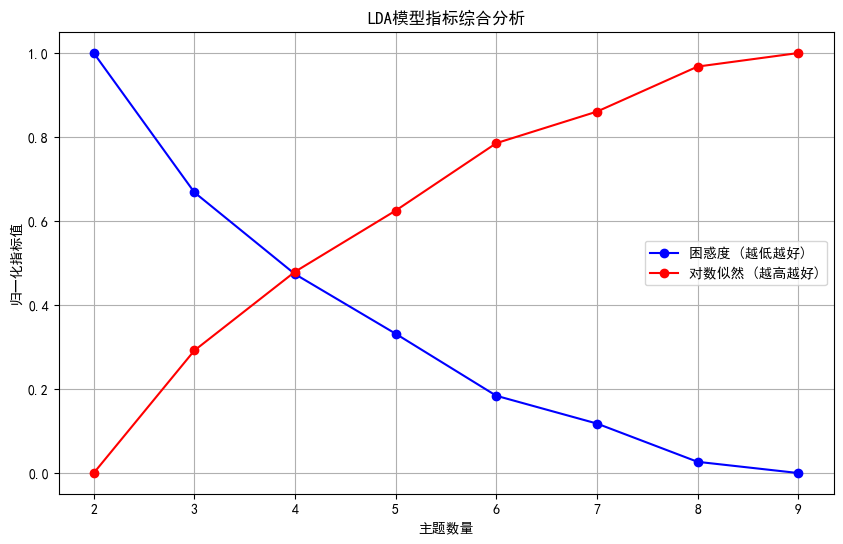

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# ====== 综合可视化 ======
plt.figure(figsize=(10, 6))

# 归一化指标 (把两个指标缩放到 0~1 之间)
perplexity_norm = (perplexities - np.min(perplexities)) / (np.max(perplexities) - np.min(perplexities))
likelihood_norm = (log_likelihoods - np.min(log_likelihoods)) / (np.max(log_likelihoods) - np.min(log_likelihoods))

# 画线
plt.plot(topics_range, perplexity_norm, 'bo-', label='困惑度 (越低越好)')
plt.plot(topics_range, likelihood_norm, 'ro-', label='对数似然 (越高越好)')

plt.xlabel('主题数量')
plt.ylabel('归一化指标值')
plt.title('LDA模型指标综合分析')

# 解决中文字体显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.legend()
plt.grid(True)
plt.show()

正在进行情感分析，请稍候...

===== 情感分布统计 =====
sentiment_label
负面 (差评)    74264
中性          5453
正面 (好评)     4535
Name: count, dtype: int64


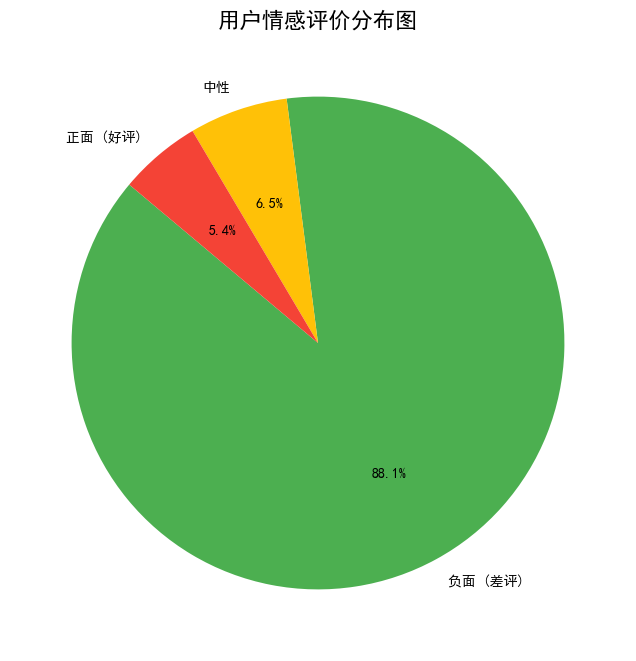


✅ 情感分析结果已保存至: D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\情感分析结果.csv


In [11]:
from snownlp import SnowNLP
import matplotlib.pyplot as plt
import pandas as pd

print("正在进行情感分析，请稍候...")

# 1. 写一个计算情感分数的函数（返回 0-1 之间的数值）
def get_sentiment(text):
    try:
        return SnowNLP(str(text)).sentiments
    except:
        return 0.5 # 如果遇到空值或错误，给个中间值

# 2. 应用到你的 DataFrame 里（因为 8 万多条数据，可能要跑个几十秒）
df['sentiment_score'] = df['records'].apply(get_sentiment)

# 3. 定义情感分类（大于0.6算正面，小于0.4算负面，中间算中性）
def classify_sentiment(score):
    if score >= 0.6:
        return '正面 (好评)'
    elif score <= 0.4:
        return '负面 (差评)'
    else:
        return '中性'

df['sentiment_label'] = df['sentiment_score'].apply(classify_sentiment)

# 4. 统计一下好评差评的比例
sentiment_counts = df['sentiment_label'].value_counts()
print("\n===== 情感分布统计 =====")
print(sentiment_counts)

# 5. 画个饼图看看
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 8))
plt.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%',
        colors=['#4CAF50', '#FFC107', '#F44336'], startangle=140)
plt.title('用户情感评价分布图', fontsize=16)
plt.show()

# 6. 把结果存下来，供后面的大屏用（路径你自己改）
save_path = 'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\情感分析结果.csv'
df[['id', 'time', 'records', 'sentiment_score', 'sentiment_label']].to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"\n✅ 情感分析结果已保存至: {save_path}")